,n_estimators,max_depth,accuracy,precision,recall
0,50,3.0,0.947368,0.958333,0.958333
1,100,5.0,0.956140,0.958904,0.972222
2,100,NaN,0.956140,0.958904,0.972222
3,200,NaN,0.956140,0.958904,0.972222


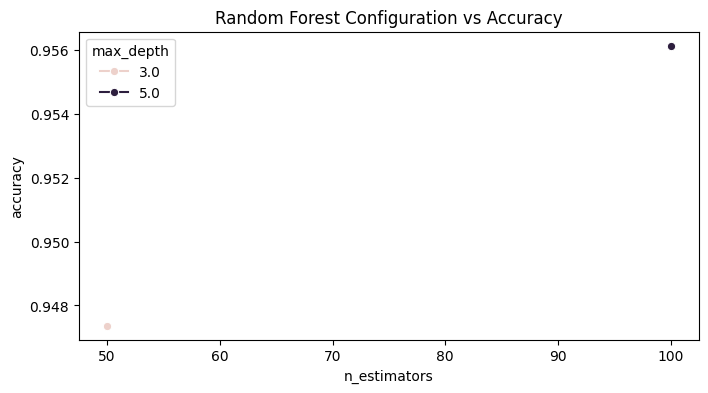

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



,Importance
worst perimeter,0.133100
worst area,0.128052
worst concave points,0.108107
mean concave points,0.094414
worst radius,0.090639
mean radius,0.058662
mean perimeter,0.055242
mean area,0.049938
mean concavity,0.046207
worst concavity,0.035357


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

configs = [
    {"n_estimators":50, "max_depth":3},
    {"n_estimators":100, "max_depth":5},
    {"n_estimators":100, "max_depth":None},
    {"n_estimators":200, "max_depth":None}
]
rows = []
for cfg in configs:
    rf = RandomForestClassifier(**cfg, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    p = rf.predict(X_test)
    rows.append({**cfg, "accuracy":accuracy_score(y_test,p),
                 "precision":precision_score(y_test,p),
                 "recall":recall_score(y_test,p)})
results = pd.DataFrame(rows)
display(results)

plt.figure(figsize=(8,4))
sns.lineplot(data=results, x="n_estimators", y="accuracy",
             hue="max_depth", marker="o", errorbar=None)
plt.title("Random Forest Configuration vs Accuracy")
plt.show()

final_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
final_model.fit(X_train, y_train)
final_pred = final_model.predict(X_test)
print(classification_report(y_test, final_pred, target_names=data.target_names))

importance = pd.Series(final_model.feature_importances_, index=X.columns)
display(importance.sort_values(ascending=False).head(10).to_frame("Importance"))